In [1]:
# Cell 1: Install & Import
!pip install scikit-fuzzy matplotlib numpy

import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 12.8 MB/s eta 0:00:00


In [2]:
# Cell 2: Define Inputs and Output Variables
engine_temp = ctrl.Antecedent(np.arange(0, 121, 1), 'engine_temp')
coolant_temp = ctrl.Antecedent(np.arange(0, 121, 1), 'coolant_temp')
env_temp = ctrl.Antecedent(np.arange(0, 51, 1), 'env_temp')

fan_duration = ctrl.Consequent(np.arange(0, 31, 1), 'fan_duration')

In [3]:
# Cell 3: Define Membership Functions
# Engine Temperature
engine_temp['cool'] = fuzz.trimf(engine_temp.universe, [0, 0, 70])
engine_temp['normal'] = fuzz.trimf(engine_temp.universe, [50, 80, 100])
engine_temp['hot'] = fuzz.trimf(engine_temp.universe, [85, 115, 120])

# Coolant Temperature
coolant_temp['low'] = fuzz.trimf(coolant_temp.universe, [0, 0, 60])
coolant_temp['normal'] = fuzz.trimf(coolant_temp.universe, [40, 75, 95])
coolant_temp['high'] = fuzz.trimf(coolant_temp.universe, [80, 110, 120])

# Environmental Temperature
env_temp['cold'] = fuzz.trimf(env_temp.universe, [0, 0, 20])
env_temp['mild'] = fuzz.trimf(env_temp.universe, [10, 25, 38])
env_temp['hot'] = fuzz.trimf(env_temp.universe, [30, 50, 50])

# Radiator Fan Duration (Output)
fan_duration['off'] = fuzz.trimf(fan_duration.universe, [0, 0, 5])
fan_duration['short'] = fuzz.trimf(fan_duration.universe, [3, 8, 15])
fan_duration['medium'] = fuzz.trimf(fan_duration.universe, [10, 18, 25])
fan_duration['long'] = fuzz.trimf(fan_duration.universe, [20, 28, 30])

In [4]:
# Cell 4: Create Rule Base
r1 = ctrl.Rule(engine_temp['hot'] & coolant_temp['high'] & env_temp['hot'], fan_duration['long'])
r2 = ctrl.Rule(engine_temp['hot'] & coolant_temp['high'] & env_temp['mild'], fan_duration['long'])
r3 = ctrl.Rule(engine_temp['hot'] & coolant_temp['normal'] & env_temp['hot'], fan_duration['medium'])
r4 = ctrl.Rule(engine_temp['normal'] & coolant_temp['high'] & env_temp['hot'], fan_duration['medium'])
r5 = ctrl.Rule(engine_temp['normal'] & coolant_temp['normal'] & env_temp['mild'], fan_duration['short'])
r6 = ctrl.Rule(engine_temp['cool'] & coolant_temp['low'] & env_temp['cold'], fan_duration['off'])
r7 = ctrl.Rule(engine_temp['normal'] & coolant_temp['low'] & env_temp['cold'], fan_duration['off'])
r8 = ctrl.Rule(engine_temp['cool'] & coolant_temp['high'] & env_temp['hot'], fan_duration['short'])

# Build Control System Simulation
cooling_ctrl = ctrl.ControlSystem([r1, r2, r3, r4, r5, r6, r7, r8])
cooling_sim = ctrl.ControlSystemSimulation(cooling_ctrl)

In [5]:
# Cell 5: Provide Live Inputs and Calculate Output
cooling_sim.input['engine_temp'] = 92
cooling_sim.input['coolant_temp'] = 88
cooling_sim.input['env_temp'] = 35

cooling_sim.compute()

# Print the final result
print(f"Recommended Fan Duration: {cooling_sim.output['fan_duration']:.2f} minutes")

Recommended Fan Duration: 16.73 minutes


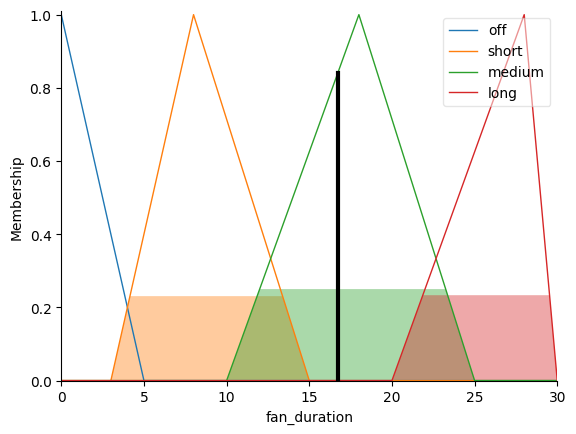

In [6]:
# Cell 6: Visualize Defuzzification
fan_duration.view(sim=cooling_sim)
plt.show()

In [7]:
# Test Case 1: Winter Cold Start
e_val = 15
c_val = 10
env_val = 5

cooling_sim.input['engine_temp'] = e_val
cooling_sim.input['coolant_temp'] = c_val
cooling_sim.input['env_temp'] = env_val

cooling_sim.compute()

print("--- Test Case 1: Winter Cold Start ---")
print(f"Engine Temp : {e_val} °C")
print(f"Coolant Temp: {c_val} °C")
print(f"Ambient Temp: {env_val} °C")
print(f"Fan Duration: {cooling_sim.output['fan_duration']:.2f} minutes")

--- Test Case 1: Winter Cold Start ---
Engine Temp : 15 °C
Coolant Temp: 10 °C
Ambient Temp: 5 °C
Fan Duration: 1.75 minutes


In [8]:
# Test Case 2: Mild City Warming Up
e_val = 45
c_val = 35
env_val = 18

cooling_sim.input['engine_temp'] = e_val
cooling_sim.input['coolant_temp'] = c_val
cooling_sim.input['env_temp'] = env_val

cooling_sim.compute()

print("--- Test Case 2: Mild City Warming Up ---")
print(f"Engine Temp : {e_val} °C")
print(f"Coolant Temp: {c_val} °C")
print(f"Ambient Temp: {env_val} °C")
print(f"Fan Duration: {cooling_sim.output['fan_duration']:.2f} minutes")

--- Test Case 2: Mild City Warming Up ---
Engine Temp : 45 °C
Coolant Temp: 35 °C
Ambient Temp: 18 °C
Fan Duration: 2.38 minutes


In [9]:
# Test Case 3: Normal City Commute
e_val = 80
c_val = 75
env_val = 25

cooling_sim.input['engine_temp'] = e_val
cooling_sim.input['coolant_temp'] = c_val
cooling_sim.input['env_temp'] = env_val

cooling_sim.compute()

print("--- Test Case 3: Normal City Commute ---")
print(f"Engine Temp : {e_val} °C")
print(f"Coolant Temp: {c_val} °C")
print(f"Ambient Temp: {env_val} °C")
print(f"Fan Duration: {cooling_sim.output['fan_duration']:.2f} minutes")

--- Test Case 3: Normal City Commute ---
Engine Temp : 80 °C
Coolant Temp: 75 °C
Ambient Temp: 25 °C
Fan Duration: 8.67 minutes


In [10]:
# Test Case 4: Mild Day High Load
e_val = 92
c_val = 85
env_val = 24

cooling_sim.input['engine_temp'] = e_val
cooling_sim.input['coolant_temp'] = c_val
cooling_sim.input['env_temp'] = env_val

cooling_sim.compute()

print("--- Test Case 4: Mild Day High Load ---")
print(f"Engine Temp : {e_val} °C")
print(f"Coolant Temp: {c_val} °C")
print(f"Ambient Temp: {env_val} °C")
print(f"Fan Duration: {cooling_sim.output['fan_duration']:.2f} minutes")

--- Test Case 4: Mild Day High Load ---
Engine Temp : 92 °C
Coolant Temp: 85 °C
Ambient Temp: 24 °C
Fan Duration: 13.49 minutes


In [11]:
# Test Case 5: Standard Worked Example
e_val = 92
c_val = 88
env_val = 35

cooling_sim.input['engine_temp'] = e_val
cooling_sim.input['coolant_temp'] = c_val
cooling_sim.input['env_temp'] = env_val

cooling_sim.compute()

print("--- Test Case 5: Standard Worked Example ---")
print(f"Engine Temp : {e_val} °C")
print(f"Coolant Temp: {c_val} °C")
print(f"Ambient Temp: {env_val} °C")
print(f"Fan Duration: {cooling_sim.output['fan_duration']:.2f} minutes")

--- Test Case 5: Standard Worked Example ---
Engine Temp : 92 °C
Coolant Temp: 88 °C
Ambient Temp: 35 °C
Fan Duration: 16.73 minutes


In [12]:
# Test Case 6: Summer Highway Cruising
e_val = 85
c_val = 95
env_val = 38

cooling_sim.input['engine_temp'] = e_val
cooling_sim.input['coolant_temp'] = c_val
cooling_sim.input['env_temp'] = env_val

cooling_sim.compute()

print("--- Test Case 6: Summer Highway Cruising ---")
print(f"Engine Temp : {e_val} °C")
print(f"Coolant Temp: {c_val} °C")
print(f"Ambient Temp: {env_val} °C")
print(f"Fan Duration: {cooling_sim.output['fan_duration']:.2f} minutes")

--- Test Case 6: Summer Highway Cruising ---
Engine Temp : 85 °C
Coolant Temp: 95 °C
Ambient Temp: 38 °C
Fan Duration: 17.59 minutes


In [13]:
# Test Case 7: Desert Traffic Jam
e_val = 105
c_val = 100
env_val = 42

cooling_sim.input['engine_temp'] = e_val
cooling_sim.input['coolant_temp'] = c_val
cooling_sim.input['env_temp'] = env_val

cooling_sim.compute()

print("--- Test Case 7: Desert Traffic Jam ---")
print(f"Engine Temp : {e_val} °C")
print(f"Coolant Temp: {c_val} °C")
print(f"Ambient Temp: {env_val} °C")
print(f"Fan Duration: {cooling_sim.output['fan_duration']:.2f} minutes")

--- Test Case 7: Desert Traffic Jam ---
Engine Temp : 105 °C
Coolant Temp: 100 °C
Ambient Temp: 42 °C
Fan Duration: 25.77 minutes


In [14]:
# Test Case 8: Heavy Desert Towing
e_val = 118
c_val = 112
env_val = 48

cooling_sim.input['engine_temp'] = e_val
cooling_sim.input['coolant_temp'] = c_val
cooling_sim.input['env_temp'] = env_val

cooling_sim.compute()

print("--- Test Case 8: Heavy Desert Towing ---")
print(f"Engine Temp : {e_val} °C")
print(f"Coolant Temp: {c_val} °C")
print(f"Ambient Temp: {env_val} °C")
print(f"Fan Duration: {cooling_sim.output['fan_duration']:.2f} minutes")

--- Test Case 8: Heavy Desert Towing ---
Engine Temp : 118 °C
Coolant Temp: 112 °C
Ambient Temp: 48 °C
Fan Duration: 25.55 minutes


In [15]:
e_val = 30
c_val = 40
env_val = 45

cooling_sim.input['engine_temp'] = e_val
cooling_sim.input['coolant_temp'] = c_val
cooling_sim.input['env_temp'] = env_val

cooling_sim.compute()

print("--- Test Case 9: Cool Engine with Hot Ambient Air ---")
print(f"Engine Temp : {e_val} °C")
print(f"Coolant Temp: {c_val} °C")
print(f"Ambient Temp: {env_val} °C")

# Check if 'fan_duration' key exists before attempting to access it
if 'fan_duration' in cooling_sim.output:
    print(f"Fan Duration: {cooling_sim.output['fan_duration']:.2f} minutes")
else:
    print("Fan Duration: No specific fan duration was determined by the fuzzy rules for these inputs.")

--- Test Case 9: Cool Engine with Hot Ambient Air ---
Engine Temp : 30 °C
Coolant Temp: 40 °C
Ambient Temp: 45 °C
Fan Duration: No specific fan duration was determined by the fuzzy rules for these inputs.


In [16]:
# Test Case 10: Hot Engine in Freezing Weather
e_val = 95
c_val = 80
env_val = 10

cooling_sim.input['engine_temp'] = e_val
cooling_sim.input['coolant_temp'] = c_val
cooling_sim.input['env_temp'] = env_val

cooling_sim.compute()

print("--- Test Case 10: Hot Engine in Freezing Weather ---")
print(f"Engine Temp : {e_val} °C")
print(f"Coolant Temp: {c_val} °C")
print(f"Ambient Temp: {env_val} °C")

# Check if 'fan_duration' key exists before attempting to access it
if 'fan_duration' in cooling_sim.output:
    print(f"Fan Duration: {cooling_sim.output['fan_duration']:.2f} minutes")
else:
    print("Fan Duration: No specific fan duration was determined by the fuzzy rules for these inputs.")

--- Test Case 10: Hot Engine in Freezing Weather ---
Engine Temp : 95 °C
Coolant Temp: 80 °C
Ambient Temp: 10 °C
Fan Duration: No specific fan duration was determined by the fuzzy rules for these inputs.
